In [1]:
%pip install networkx matplotlib numpy pandas scipy scikit-learn python-louvain python-igraph leidenalg

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



Loading Facebook dataset...
Facebook loaded successfully
Nodes: 4039
Edges: 88234

Loading Twitter dataset...
Twitter loaded successfully
Nodes: 81306
Edges: 1342296

Calculating Facebook graph statistics...

Calculating Twitter graph statistics...


FACEBOOK VS TWITTER - DATASET COMPARISON
 Dataset  Nodes   Edges  Average Degree  Density  Average Clustering  Transitivity  Connected Components  Largest Component Nodes  Largest Component Percentage
Facebook   4039   88234         43.6910 0.010820              0.6055        0.5192                     1                     4039                         100.0
 Twitter  81306 1342296         33.0184 0.000406              0.5653        0.1706                     1                    81306                         100.0

Preparing Facebook connected sample...
Facebook sample: 4000 nodes, 87545 edges

Preparing Twitter connected sample...
Twitter sample: 4000 nodes, 62198 edges


FACEBOOK COMMUNITY DETECTION

Running Louvain...
Louvain communit

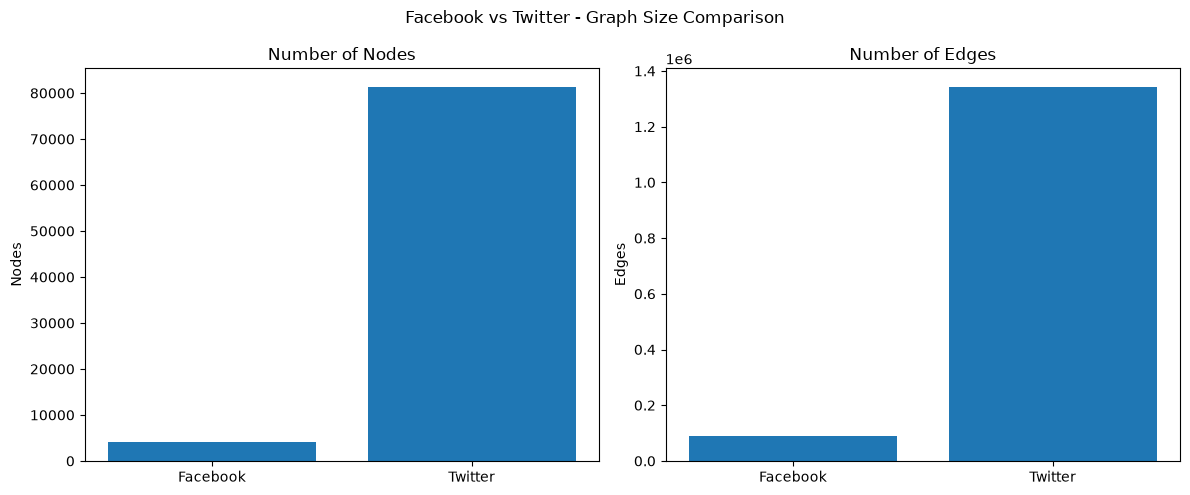

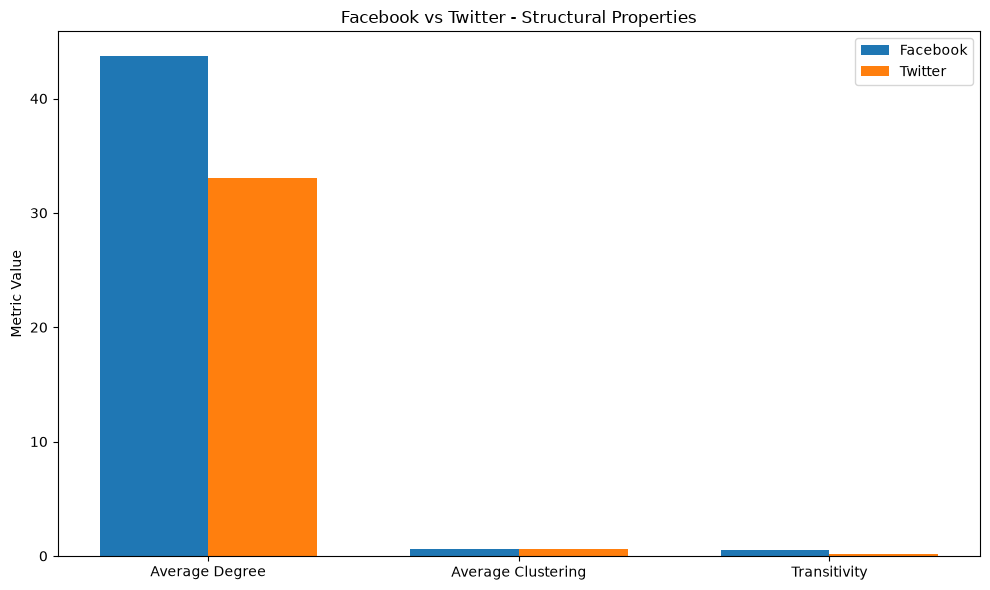

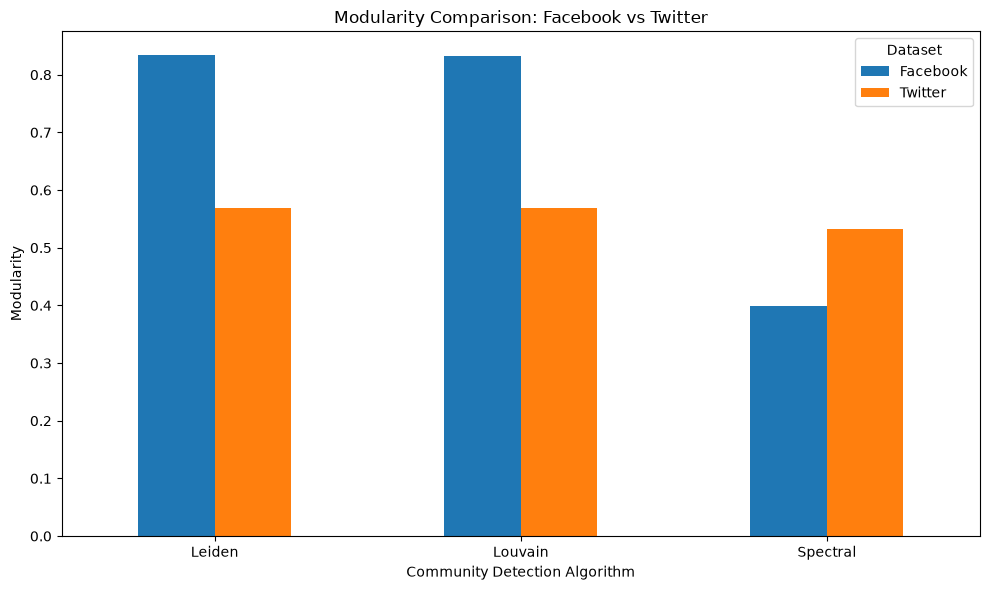

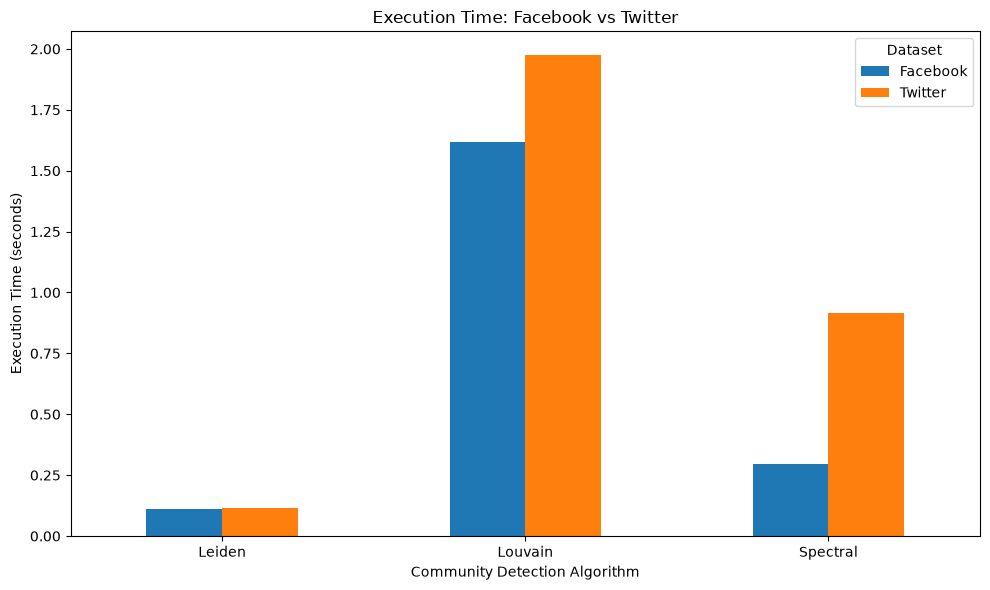



FACEBOOK VS TWITTER COMPARISON COMPLETED

Full Dataset Comparison:
 Dataset  Nodes   Edges  Average Degree  Density  Average Clustering  Transitivity  Connected Components  Largest Component Nodes  Largest Component Percentage
Facebook   4039   88234         43.6910 0.010820              0.6055        0.5192                     1                     4039                         100.0
 Twitter  81306 1342296         33.0184 0.000406              0.5653        0.1706                     1                    81306                         100.0

Community Algorithm Comparison:
 Dataset Algorithm  Nodes  Edges  Communities  Modularity  Execution Time (sec)
Facebook   Louvain   4000  87545           16      0.8329                1.6187
Facebook  Spectral   4000  87545            5      0.3991                0.2959
Facebook    Leiden   4000  87545           16      0.8336                0.1126
 Twitter   Louvain   4000  62198           15      0.5682                1.9736
 Twitter  Spectral

In [2]:

# ============================================================
# FACEBOOK vs TWITTER DATASET COMPARISON
# GNN PROJECT - FINAL PANEL REVIEW
#
# Dataset comparison:
# 1. Number of nodes
# 2. Number of edges
# 3. Average degree
# 4. Graph density
# 5. Average clustering coefficient
# 6. Connected components
# 7. Largest connected component
#
# Community detection comparison:
# 1. Louvain
# 2. Spectral Clustering
# 3. Leiden
#
# Both algorithms are tested on comparable 4000-node
# connected subgraphs.
# ============================================================

import os
import time
import warnings
warnings.filterwarnings("ignore")

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.cluster import SpectralClustering

import community.community_louvain as community_louvain
import igraph as ig
import leidenalg


# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

FACEBOOK_PATH = r"D:\GNN Mini project\facebook_combined.txt"
TWITTER_PATH = r"D:\GNN Mini project\twitter_combined.txt"

OUTPUT_DIR = r"D:\GNN Mini project\DATASET_COMPARISON"

SAMPLE_SIZE = 4000
SPECTRAL_K = 5
RANDOM_SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD DATASETS
# ============================================================

def load_graph(path, dataset_name):

    print(f"\nLoading {dataset_name} dataset...")

    if not os.path.exists(path):
        raise FileNotFoundError(f"Dataset not found: {path}")

    G = nx.read_edgelist(path, nodetype=int)

    # Remove self-loops
    G.remove_edges_from(nx.selfloop_edges(G))

    # Ensure undirected simple graph
    G = nx.Graph(G)

    print(f"{dataset_name} loaded successfully")
    print("Nodes:", G.number_of_nodes())
    print("Edges:", G.number_of_edges())

    return G


G_facebook = load_graph(FACEBOOK_PATH, "Facebook")
G_twitter = load_graph(TWITTER_PATH, "Twitter")


# ============================================================
# 3. DATASET-LEVEL STATISTICS
# ============================================================

def calculate_graph_statistics(G, dataset_name):

    print(f"\nCalculating {dataset_name} graph statistics...")

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    components = list(nx.connected_components(G))
    largest_component = max(components, key=len)

    average_degree = (
        sum(dict(G.degree()).values()) / nodes
        if nodes else 0
    )

    density = nx.density(G)

    average_clustering = nx.average_clustering(G)

    transitivity = nx.transitivity(G)

    return {
        "Dataset": dataset_name,
        "Nodes": nodes,
        "Edges": edges,
        "Average Degree": round(average_degree, 4),
        "Density": round(density, 6),
        "Average Clustering": round(average_clustering, 4),
        "Transitivity": round(transitivity, 4),
        "Connected Components": len(components),
        "Largest Component Nodes": len(largest_component),
        "Largest Component Percentage": round(
            100 * len(largest_component) / nodes, 2
        )
    }


facebook_stats = calculate_graph_statistics(
    G_facebook, "Facebook"
)

twitter_stats = calculate_graph_statistics(
    G_twitter, "Twitter"
)

dataset_df = pd.DataFrame([
    facebook_stats,
    twitter_stats
])

print("\n")
print("=" * 85)
print("FACEBOOK VS TWITTER - DATASET COMPARISON")
print("=" * 85)

print(dataset_df.to_string(index=False))

dataset_df.to_csv(
    os.path.join(OUTPUT_DIR, "dataset_comparison.csv"),
    index=False
)


# ============================================================
# 4. EXTRACT COMPARABLE CONNECTED SUBGRAPHS
# ============================================================

def get_connected_sample(G, sample_size, dataset_name):

    print(f"\nPreparing {dataset_name} connected sample...")

    largest_component = max(
        nx.connected_components(G),
        key=len
    )

    H = G.subgraph(largest_component).copy()

    if H.number_of_nodes() < sample_size:
        raise ValueError(
            f"{dataset_name} has fewer than {sample_size} "
            "nodes in its largest connected component."
        )

    # Start from highest-degree node
    start_node = max(
        H.degree,
        key=lambda item: item[1]
    )[0]

    # BFS ensures selected nodes are connected
    bfs_nodes = list(
        nx.bfs_tree(H, start_node).nodes()
    )

    selected_nodes = bfs_nodes[:sample_size]

    sample = H.subgraph(selected_nodes).copy()

    if not nx.is_connected(sample):
        raise ValueError(
            f"{dataset_name} sample is unexpectedly disconnected."
        )

    print(
        f"{dataset_name} sample: "
        f"{sample.number_of_nodes()} nodes, "
        f"{sample.number_of_edges()} edges"
    )

    return sample


G_fb_sample = get_connected_sample(
    G_facebook, SAMPLE_SIZE, "Facebook"
)

G_tw_sample = get_connected_sample(
    G_twitter, SAMPLE_SIZE, "Twitter"
)


# ============================================================
# 5. COMMUNITY DETECTION FUNCTION
# ============================================================

def run_community_algorithms(G, dataset_name):

    print("\n")
    print("=" * 85)
    print(f"{dataset_name.upper()} COMMUNITY DETECTION")
    print("=" * 85)

    results = []

    nodes = list(G.nodes())

    # --------------------------------------------------------
    # LOUVAIN
    # --------------------------------------------------------

    print("\nRunning Louvain...")

    start = time.perf_counter()

    louvain_partition = community_louvain.best_partition(
        G,
        random_state=RANDOM_SEED
    )

    louvain_time = time.perf_counter() - start

    louvain_groups = {}

    for node, cid in louvain_partition.items():
        louvain_groups.setdefault(cid, set()).add(node)

    louvain_communities = list(louvain_groups.values())

    louvain_modularity = nx.community.modularity(
        G, louvain_communities
    )

    results.append({
        "Dataset": dataset_name,
        "Algorithm": "Louvain",
        "Nodes": G.number_of_nodes(),
        "Edges": G.number_of_edges(),
        "Communities": len(louvain_communities),
        "Modularity": round(louvain_modularity, 4),
        "Execution Time (sec)": round(louvain_time, 4)
    })

    print("Louvain communities:", len(louvain_communities))
    print("Louvain modularity:", round(louvain_modularity, 4))
    print("Louvain time:", round(louvain_time, 4), "seconds")


    # --------------------------------------------------------
    # SPECTRAL CLUSTERING
    # --------------------------------------------------------

    print("\nRunning Spectral Clustering...")

    start = time.perf_counter()

    adjacency = nx.to_scipy_sparse_array(
        G,
        nodelist=nodes,
        dtype=np.float64,
        format="csr"
    )

    spectral_model = SpectralClustering(
        n_clusters=SPECTRAL_K,
        affinity="precomputed",
        assign_labels="kmeans",
        eigen_solver="arpack",
        random_state=RANDOM_SEED,
        n_init=10
    )

    spectral_labels = spectral_model.fit_predict(
        csr_matrix(adjacency)
    )

    spectral_time = time.perf_counter() - start

    spectral_partition = {
        node: int(label)
        for node, label in zip(nodes, spectral_labels)
    }

    spectral_groups = {}

    for node, cid in spectral_partition.items():
        spectral_groups.setdefault(cid, set()).add(node)

    spectral_communities = list(spectral_groups.values())

    spectral_modularity = nx.community.modularity(
        G, spectral_communities
    )

    results.append({
        "Dataset": dataset_name,
        "Algorithm": "Spectral",
        "Nodes": G.number_of_nodes(),
        "Edges": G.number_of_edges(),
        "Communities": len(spectral_communities),
        "Modularity": round(spectral_modularity, 4),
        "Execution Time (sec)": round(spectral_time, 4)
    })

    print("Spectral communities:", len(spectral_communities))
    print("Spectral modularity:", round(spectral_modularity, 4))
    print("Spectral time:", round(spectral_time, 4), "seconds")


    # --------------------------------------------------------
    # LEIDEN
    # --------------------------------------------------------

    print("\nRunning Leiden...")

    start = time.perf_counter()

    # Explicit node mapping preserves original node identities
    node_to_index = {
        node: index
        for index, node in enumerate(nodes)
    }

    indexed_edges = [
        (node_to_index[u], node_to_index[v])
        for u, v in G.edges()
    ]

    igraph_graph = ig.Graph(
        n=len(nodes),
        edges=indexed_edges,
        directed=False
    )

    leiden_result = leidenalg.find_partition(
        igraph_graph,
        leidenalg.ModularityVertexPartition,
        seed=RANDOM_SEED
    )

    leiden_time = time.perf_counter() - start

    leiden_partition = {
        node: int(cid)
        for node, cid in zip(
            nodes,
            leiden_result.membership
        )
    }

    leiden_groups = {}

    for node, cid in leiden_partition.items():
        leiden_groups.setdefault(cid, set()).add(node)

    leiden_communities = list(leiden_groups.values())

    leiden_modularity = nx.community.modularity(
        G, leiden_communities
    )

    results.append({
        "Dataset": dataset_name,
        "Algorithm": "Leiden",
        "Nodes": G.number_of_nodes(),
        "Edges": G.number_of_edges(),
        "Communities": len(leiden_communities),
        "Modularity": round(leiden_modularity, 4),
        "Execution Time (sec)": round(leiden_time, 4)
    })

    print("Leiden communities:", len(leiden_communities))
    print("Leiden modularity:", round(leiden_modularity, 4))
    print("Leiden time:", round(leiden_time, 4), "seconds")

    return results


# ============================================================
# 6. RUN ALL THREE ALGORITHMS ON BOTH DATASETS
# ============================================================

facebook_results = run_community_algorithms(
    G_fb_sample,
    "Facebook"
)

twitter_results = run_community_algorithms(
    G_tw_sample,
    "Twitter"
)

algorithm_df = pd.DataFrame(
    facebook_results + twitter_results
)

print("\n")
print("=" * 100)
print("COMMUNITY DETECTION COMPARISON")
print("=" * 100)

print(algorithm_df.to_string(index=False))

algorithm_df.to_csv(
    os.path.join(OUTPUT_DIR, "community_algorithm_comparison.csv"),
    index=False
)


# ============================================================
# 7. VISUALIZATION 1 - NODES AND EDGES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    ["Facebook", "Twitter"],
    [facebook_stats["Nodes"], twitter_stats["Nodes"]]
)

axes[0].set_title("Number of Nodes")
axes[0].set_ylabel("Nodes")

axes[1].bar(
    ["Facebook", "Twitter"],
    [facebook_stats["Edges"], twitter_stats["Edges"]]
)

axes[1].set_title("Number of Edges")
axes[1].set_ylabel("Edges")

plt.suptitle("Facebook vs Twitter - Graph Size Comparison")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "graph_size_comparison.png"),
    dpi=300
)

plt.show()


# ============================================================
# 8. VISUALIZATION 2 - GRAPH STRUCTURAL PROPERTIES
# ============================================================

metrics = [
    "Average Degree",
    "Average Clustering",
    "Transitivity"
]

x = np.arange(len(metrics))
width = 0.35

fb_values = [
    facebook_stats[m] for m in metrics
]

tw_values = [
    twitter_stats[m] for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    fb_values,
    width,
    label="Facebook"
)

plt.bar(
    x + width / 2,
    tw_values,
    width,
    label="Twitter"
)

plt.xticks(x, metrics)
plt.ylabel("Metric Value")
plt.title("Facebook vs Twitter - Structural Properties")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "structural_comparison.png"),
    dpi=300
)

plt.show()


# ============================================================
# 9. VISUALIZATION 3 - MODULARITY COMPARISON
# ============================================================

pivot_modularity = algorithm_df.pivot(
    index="Algorithm",
    columns="Dataset",
    values="Modularity"
)

pivot_modularity.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Modularity Comparison: Facebook vs Twitter")
plt.ylabel("Modularity")
plt.xlabel("Community Detection Algorithm")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "modularity_comparison.png"),
    dpi=300
)

plt.show()


# ============================================================
# 10. VISUALIZATION 4 - EXECUTION TIME COMPARISON
# ============================================================

pivot_time = algorithm_df.pivot(
    index="Algorithm",
    columns="Dataset",
    values="Execution Time (sec)"
)

pivot_time.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Execution Time: Facebook vs Twitter")
plt.ylabel("Execution Time (seconds)")
plt.xlabel("Community Detection Algorithm")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "execution_time_comparison.png"),
    dpi=300
)

plt.show()


# ============================================================
# 11. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 85)
print("FACEBOOK VS TWITTER COMPARISON COMPLETED")
print("=" * 85)

print("\nFull Dataset Comparison:")
print(dataset_df.to_string(index=False))

print("\nCommunity Algorithm Comparison:")
print(algorithm_df.to_string(index=False))

print("\nFiles saved in:")
print(OUTPUT_DIR)

print("\nGenerated files:")
print("1. dataset_comparison.csv")
print("2. community_algorithm_comparison.csv")
print("3. graph_size_comparison.png")
print("4. structural_comparison.png")
print("5. modularity_comparison.png")
print("6. execution_time_comparison.png")

print("\nAll comparisons completed.")
